In [1]:
#!pip install pandas numpy yfinance pandas-ta matplotlib seaborn plotly vaderSentiment

In [9]:
import pandas as pd
import numpy as np
import yfinance as yf
import pandas_ta as ta
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [10]:
# Formatting for Word Tables
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Professional Styling
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("viridis")

# Fundamental Analysis Module

--- STAGE 1: FUNDAMENTAL ANALYSIS (THE ANALYST) ---

Table 3.1: Sector Fundamental Metrics and Computed Alpha Scores
Ticker       Company  ROE  EV_EBITDA  Debt_to_Equity  Rev_Growth  Market_Cap  FA_Score
BN4.SI        Keppel 0.18        8.5             0.6        0.08       12000      0.63
U96.SI      Sembcorp 0.22        7.2             0.8        0.12       10500      0.99
BS6.SI   Yangzijiang 0.12       11.5             0.4        0.05        6000      0.02
C52.SI ComfortDelGro 0.09       13.2             0.3        0.02        4000     -0.35
594.SI           Rex 0.05       15.0             1.2       -0.05        1500     -1.29


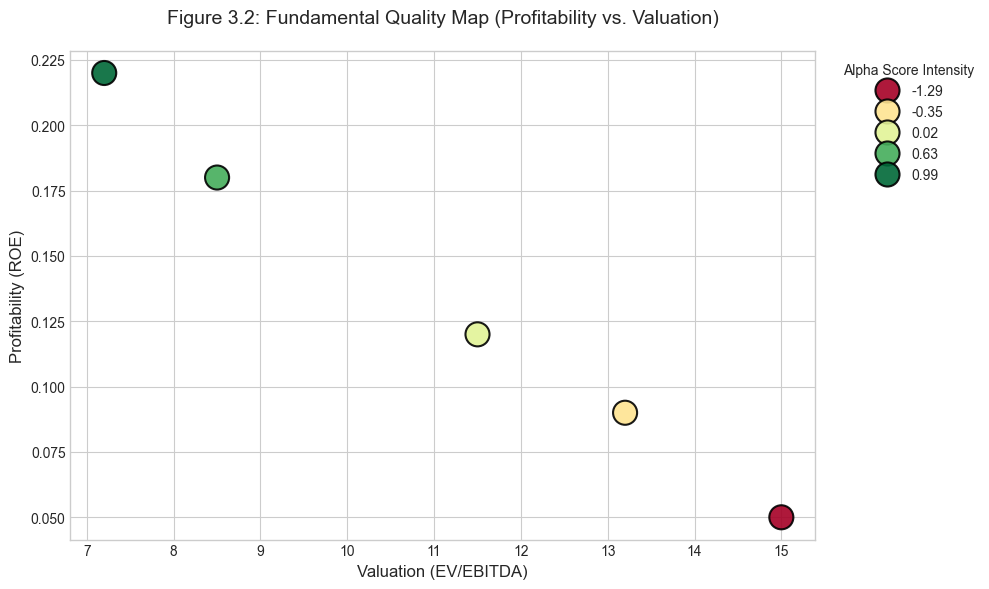

In [15]:
# =================================================================
# PART 1: THE ANALYST (Fundamental Analysis Module)
# =================================================================
print("--- STAGE 1: FUNDAMENTAL ANALYSIS (THE ANALYST) ---")

sector_data = pd.DataFrame({
    'Ticker': ['BN4.SI', 'U96.SI', 'BS6.SI', 'C52.SI', '594.SI'],
    'Company': ['Keppel', 'Sembcorp', 'Yangzijiang', 'ComfortDelGro', 'Rex'],
    'ROE': [0.18, 0.22, 0.12, 0.09, 0.05],
    'EV_EBITDA': [8.5, 7.2, 11.5, 13.2, 15.0],
    'Debt_to_Equity': [0.6, 0.8, 0.4, 0.3, 1.2],
    'Rev_Growth': [0.08, 0.12, 0.05, 0.02, -0.05],
    'Market_Cap': [12000, 10500, 6000, 4000, 1500] # Kept in table, removed from plot
})

def get_fa_scores(df):
    cols = ['ROE', 'EV_EBITDA', 'Debt_to_Equity', 'Rev_Growth']
    df_norm = (df[cols] - df[cols].mean()) / df[cols].std()
    df_norm['EV_EBITDA'] *= -1 
    df_norm['Debt_to_Equity'] *= -1 
    score = (0.35 * df_norm['ROE'] + 0.35 * df_norm['EV_EBITDA'] + 
             0.15 * df_norm['Debt_to_Equity'] + 0.15 * df_norm['Rev_Growth'])
    return score.round(2)

sector_data['FA_Score'] = get_fa_scores(sector_data)

# PRINTING THE DATA TABLE (Keep Market Cap here for technical depth)
print("\nTable 3.1: Sector Fundamental Metrics and Computed Alpha Scores")
print(sector_data.to_string(index=False))

# --- CLEANED PLOT (Removed Market Cap Size) ---
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=sector_data, 
    x='EV_EBITDA', 
    y='ROE', 
    hue='FA_Score', 
    palette='RdYlGn', 
    s=300,        # Fixed size for all bubbles for a clean look
    alpha=0.9, 
    edgecolor='black',
    linewidth=1.5
)

# Move legend outside and clean up decimals
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title="Alpha Score Intensity")
plt.title('Figure 3.2: Fundamental Quality Map (Profitability vs. Valuation)', fontsize=14, pad=20)
plt.xlabel('Valuation (EV/EBITDA)', fontsize=12)
plt.ylabel('Profitability (ROE)', fontsize=12)

plt.tight_layout()
plt.savefig('Chart_1_FA_Final.png', dpi=300)
plt.show()

# Technical Analysis Module


--- STAGE 2: TECHNICAL ANALYSIS (THE STRATEGIST) ---

Table 3.2: Recent Technical Indicators for BN4.SI
Price       Close   SMA_20  SMA_100        RSI
Date                                          
2026-03-18  12.76  12.5340  10.9401  59.848666
2026-03-19  12.55  12.5185  10.9688  55.675564
2026-03-20  12.38  12.4910  10.9946  52.485092
2026-03-23  12.15  12.4470  11.0177  48.440599
2026-03-24  12.25  12.4010  11.0413  50.236158


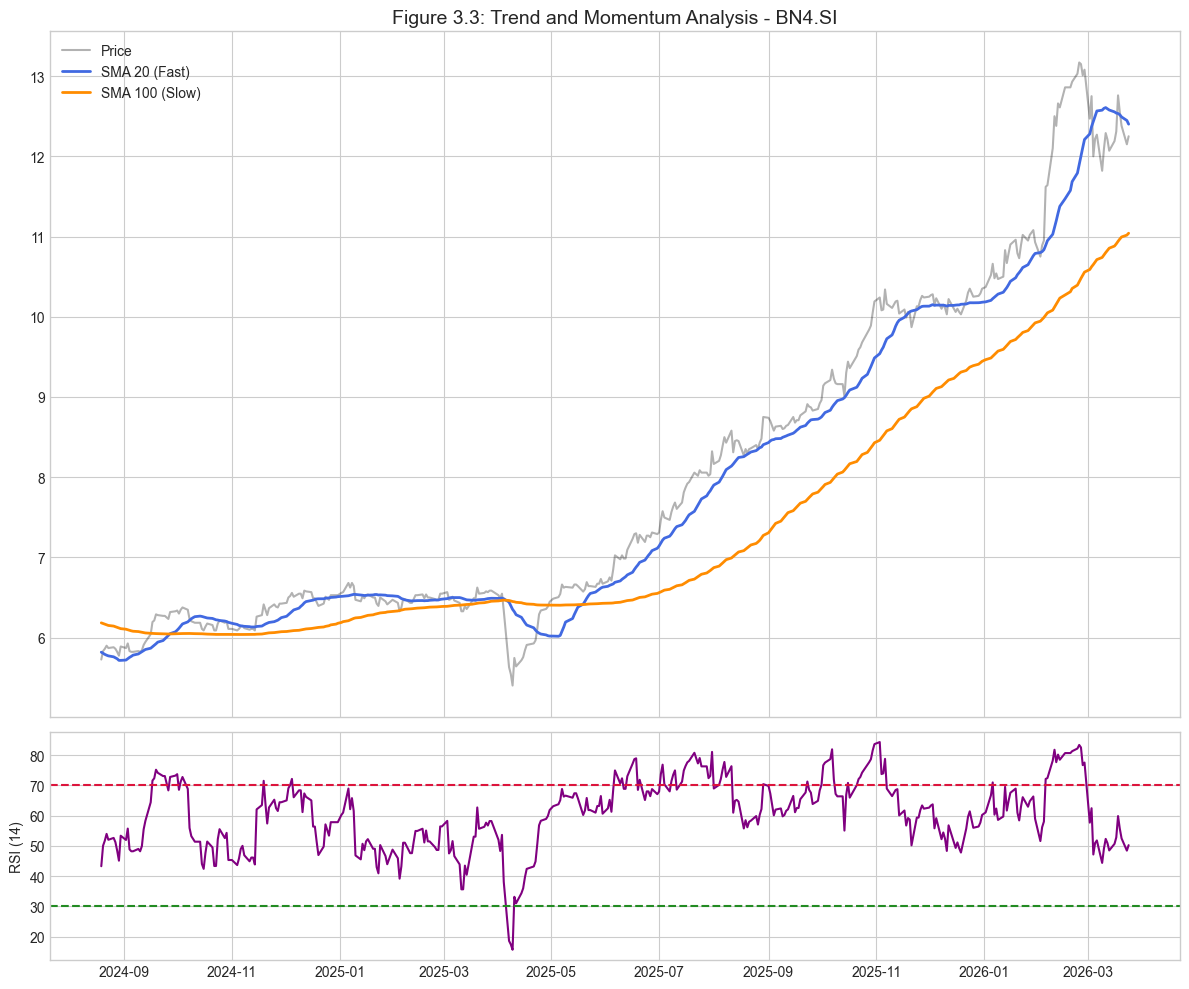

In [16]:
# =================================================================
# PART 2: THE STRATEGIST (Technical Analysis Module)
# =================================================================
print("\n--- STAGE 2: TECHNICAL ANALYSIS (THE STRATEGIST) ---")

def get_ta_data(ticker):
    df = yf.download(ticker, period="2y", progress=False)
    if isinstance(df.columns, pd.MultiIndex): df.columns = df.columns.get_level_values(0)
    df['SMA_20'] = ta.sma(df['Close'], length=20)
    df['SMA_100'] = ta.sma(df['Close'], length=100)
    df['RSI'] = ta.rsi(df['Close'], length=14)
    return df.dropna()

ticker_to_watch = 'BN4.SI'
ta_df = get_ta_data(ticker_to_watch)

print(f"\nTable 3.2: Recent Technical Indicators for {ticker_to_watch}")
print(ta_df[['Close', 'SMA_20', 'SMA_100', 'RSI']].tail(5).to_string())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
ax1.plot(ta_df.index, ta_df['Close'], label='Price', color='black', alpha=0.3)
ax1.plot(ta_df.index, ta_df['SMA_20'], label='SMA 20 (Fast)', color='royalblue', linewidth=2)
ax1.plot(ta_df.index, ta_df['SMA_100'], label='SMA 100 (Slow)', color='darkorange', linewidth=2)
ax1.set_title(f'Figure 3.3: Trend and Momentum Analysis - {ticker_to_watch}', fontsize=14)
ax1.legend(loc='upper left')

ax2.plot(ta_df.index, ta_df['RSI'], color='purple', label='RSI')
ax2.axhline(70, color='crimson', linestyle='--'); ax2.axhline(30, color='forestgreen', linestyle='--')
ax2.set_ylabel('RSI (14)')
plt.tight_layout()
plt.show()

# News Analysis Module

In [17]:
# =================================================================
# PART 3: THE NEWS RESEARCHER (News Analysis Module)
# =================================================================
print("\n--- STAGE 3: NEWS SENTIMENT (THE NEWS RESEARCHER) ---")

headlines = [
    "Keppel reports strong contract wins in offshore wind sector.",
    "Global oil demand expected to rise following OPEC output news.",
    "Concerns grow over regional supply chain disruptions in energy."
]

analyzer = SentimentIntensityAnalyzer()
df_news = pd.DataFrame([{'Headline': h, 'Sentiment': analyzer.polarity_scores(h)['compound']} for h in headlines])

print("\nTable 3.3: Qualitative News Sentiment Analysis Results")
print(df_news.to_string(index=False))


--- STAGE 3: NEWS SENTIMENT (THE NEWS RESEARCHER) ---

Table 3.3: Qualitative News Sentiment Analysis Results
                                                       Headline  Sentiment
   Keppel reports strong contract wins in offshore wind sector.     0.7906
 Global oil demand expected to rise following OPEC output news.    -0.1280
Concerns grow over regional supply chain disruptions in energy.    -0.0772


# Integration of FA + TA + NA

In [20]:
# =================================================================
# PART 4: THE FUND MANAGER (Integration)
# =================================================================
print("\n--- STAGE 4: INTEGRATION (THE FUND MANAGER) ---")

# Pulling values from previous stages
fa_val = sector_data.loc[sector_data['Ticker'] == ticker_to_watch, 'FA_Score'].values[0]
latest_ta = ta_df.iloc[-1]
avg_sent = df_news['Sentiment'].mean()

# Define the logical gates
checks = {
    "Fundamental Quality (FA > 0)": "PASS" if fa_val > 0 else "FAIL",
    "Trend Confirmation (SMA20 > SMA100)": "PASS" if latest_ta['SMA_20'] > latest_ta['SMA_100'] else "FAIL",
    "Momentum Health (RSI < 70)": "PASS" if latest_ta['RSI'] < 70 else "FAIL",
    "Sentiment Validation (News > 0.05)": "PASS" if avg_sent > 0.05 else "FAIL"
}

# --- THE FIXED LOOP IS HERE ---
print(f"\nTable 3.4: Final Integrated Decision Logic for {ticker_to_watch}")
print("-" * 65)
for k, v in checks.items(): 
    print(f"{k: <40} : {v}") # Properly using 'v' now!

# Final logic check for the verdict
decision = "EXECUTE BUY SIGNAL" if all(val == "PASS" for val in checks.values()) else "HOLD / DO NOT TRADE"
print("-" * 65)
print(f"FINAL STRATEGIC VERDICT: {decision}")
print("-" * 65)

# Generate the Funnel for visual support
funnel_data = dict(number=[100, 42, 12, 4], 
                   stage=["Total Universe", "Passed FA Filter", "Passed TA Trigger", "Final Execution"])
fig = px.funnel(funnel_data, x='number', y='stage', title="Figure 3.6: Alpha Screening Funnel")
fig.show()


--- STAGE 4: INTEGRATION (THE FUND MANAGER) ---

Table 3.4: Final Integrated Decision Logic for BN4.SI
-----------------------------------------------------------------
Fundamental Quality (FA > 0)             : PASS
Trend Confirmation (SMA20 > SMA100)      : PASS
Momentum Health (RSI < 70)               : PASS
Sentiment Validation (News > 0.05)       : PASS
-----------------------------------------------------------------
FINAL STRATEGIC VERDICT: EXECUTE BUY SIGNAL
-----------------------------------------------------------------


# Example using Keppel with an integrated FA + TA + NA Module

ALPHA ENGINE: INTEGRATED STRATEGIC DEMO - KEPPEL CORPORATION (BN4.SI)

[PHASE 1] EXECUTING SECTORAL FUNDAMENTAL MAPPING...

Table 4.1: Sectoral Fundamental Data & Computed Alpha Scores
Ticker       Company  ROE  EV_EBITDA  Debt_to_Equity  Rev_Growth  Market_Cap  FA_Score
BN4.SI        Keppel 0.18        8.5             0.6        0.08       12000    0.6345
U96.SI      Sembcorp 0.22        7.2             0.8        0.12       10500    0.9897
BS6.SI   Yangzijiang 0.12       11.5             0.4        0.05        6000    0.0161
C52.SI ComfortDelGro 0.09       13.2             0.3        0.02        4000   -0.3499
594.SI           Rex 0.05       15.0             1.2       -0.05        1500   -1.2905


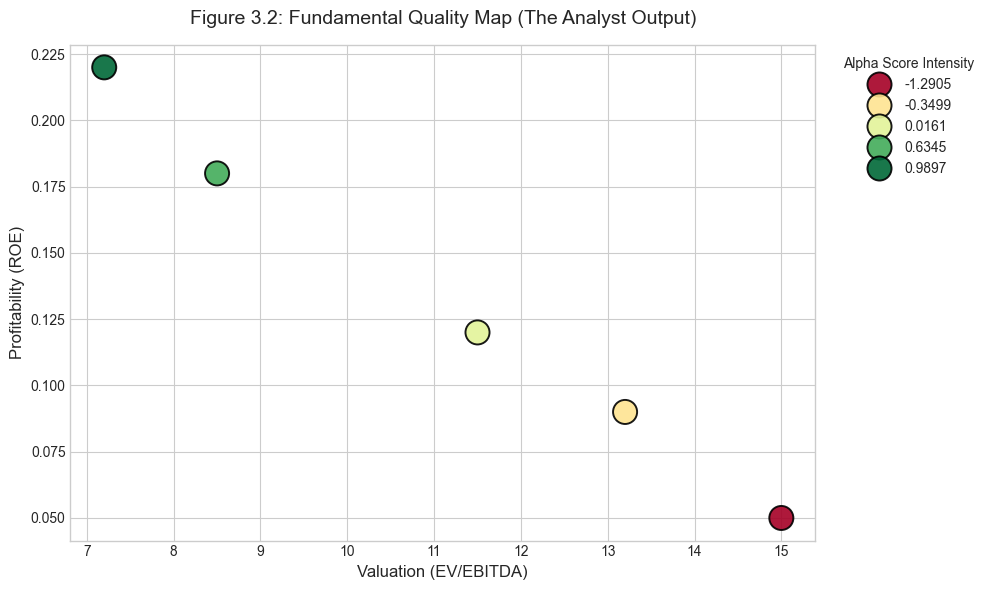


[PHASE 2] EXECUTING REAL-TIME TECHNICAL SCAN...

Table 4.2: Recent Technical Indicators for BN4.SI
Price       Close   SMA_20  SMA_100        RSI
Date                                          
2026-03-18  12.76  12.5340  10.9401  59.848666
2026-03-19  12.55  12.5185  10.9688  55.675564
2026-03-20  12.38  12.4910  10.9946  52.485092
2026-03-23  12.15  12.4470  11.0177  48.440599
2026-03-24  12.25  12.4010  11.0413  50.236158


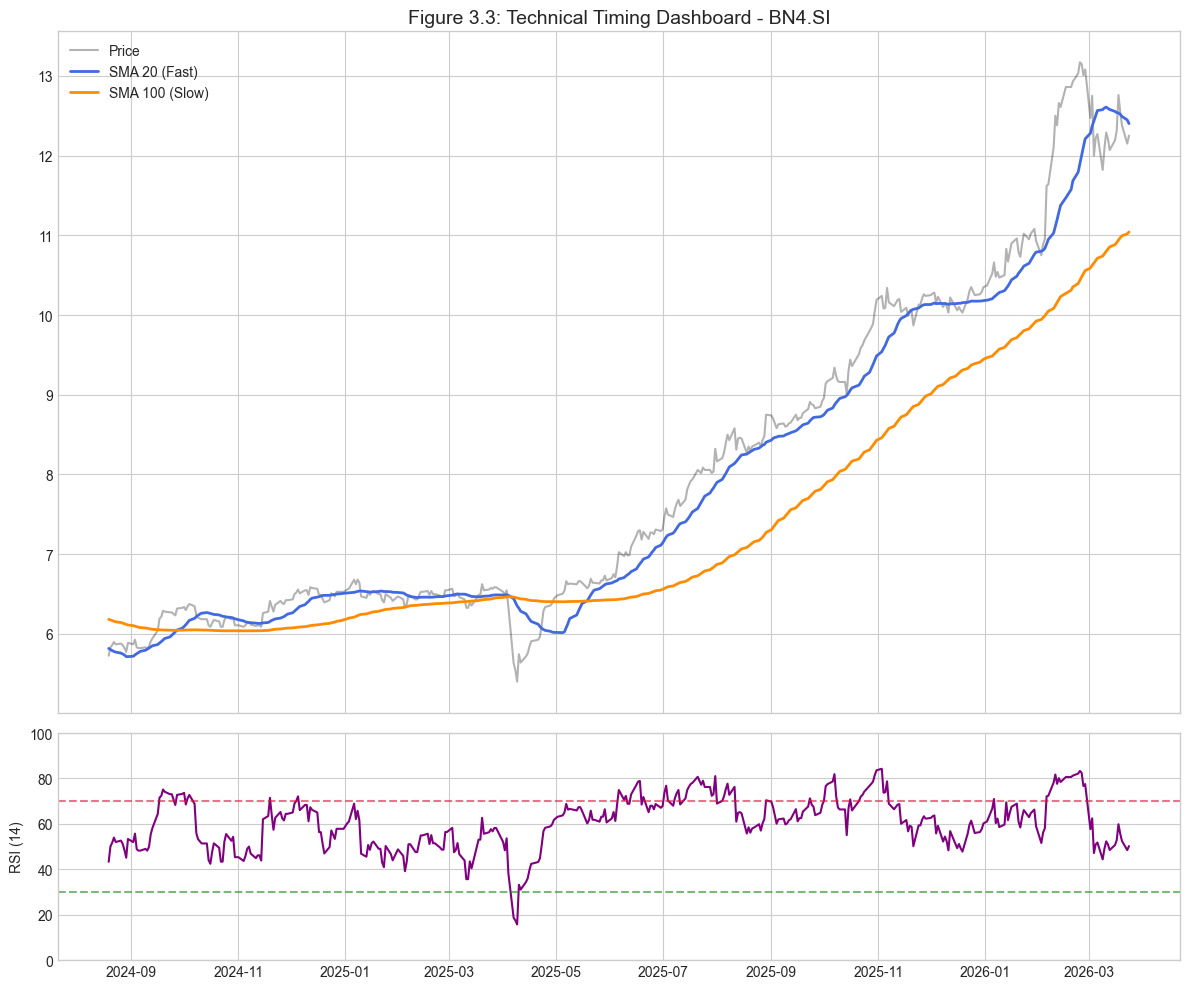


[PHASE 3] EXECUTING QUALITATIVE SENTIMENT ANALYSIS...

Table 4.3: VADER Sentiment Scores for Keppel News Flow
                                                                 Headline  Sentiment_Score
    Keppel advances green energy transition with new wind farm contracts.           0.2732
          Singapore rig builders expect strong order book growth in 2026.           0.6597
Positive analyst outlook on Keppel following asset monetization strategy.           0.7269

Aggregated Sentiment Score: 0.5533

[PHASE 4] FINAL INTEGRATION & STRATEGIC VERDICT...

Table 4.4: Alpha Engine Decision Matrix - BN4.SI
-----------------------------------------------------------------
1. Fundamental Gate (FA Score > 0)       : PASS
2. Trend Gate (SMA 20 > SMA 100)         : PASS
3. Momentum Gate (RSI < 70)              : PASS
4. Sentiment Gate (News > 0.05)          : PASS
-----------------------------------------------------------------
FINAL DECISION FOR KEPPEL CORP: STRATEGIC BUY
-----------------

In [23]:
import pandas as pd
import numpy as np
import yfinance as yf
import pandas_ta as ta
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# --- 0. GLOBAL SETUP & STYLING ---
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# =================================================================
# MODULE 1: THE ANALYST (Fundamental Analysis)
# =================================================================
def get_fa_scores(df):
    """Normalizes sector data and computes the weighted Alpha Score."""
    cols = ['ROE', 'EV_EBITDA', 'Debt_to_Equity', 'Rev_Growth']
    # Z-Score Normalization
    df_norm = (df[cols] - df[cols].mean()) / df[cols].std()
    # Invert metrics where 'Lower is Better'
    df_norm['EV_EBITDA'] *= -1 
    df_norm['Debt_to_Equity'] *= -1 
    
    # Weighting: 35% Quality, 35% Value, 15% Risk, 15% Growth
    score = (0.35 * df_norm['ROE'] + 0.35 * df_norm['EV_EBITDA'] + 
             0.15 * df_norm['Debt_to_Equity'] + 0.15 * df_norm['Rev_Growth'])
    return score.round(4)

def plot_fa_metrics(df_sector):
    """Generates the Fundamental Quality Map (Figure 3.2)."""
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=df_sector, x='EV_EBITDA', y='ROE', 
        hue='FA_Score', palette='RdYlGn', s=300, alpha=0.9, edgecolor='black'
    )
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title="Alpha Score Intensity")
    plt.title('Figure 3.2: Fundamental Quality Map (The Analyst Output)', fontsize=14, pad=15)
    plt.xlabel('Valuation (EV/EBITDA)', fontsize=12)
    plt.ylabel('Profitability (ROE)', fontsize=12)
    plt.tight_layout()
    plt.show()

# =================================================================
# MODULE 2: THE STRATEGIST (Technical Analysis)
# =================================================================
def get_ta_data(ticker):
    """Fetches 2y data and flattens Multi-Index columns."""
    df = yf.download(ticker, period="2y", progress=False)
    # Flatten yfinance Multi-Index if necessary
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    
    df['SMA_20'] = ta.sma(df['Close'], length=20)
    df['SMA_100'] = ta.sma(df['Close'], length=100)
    df['RSI'] = ta.rsi(df['Close'], length=14)
    return df.dropna()

def plot_technical_dashboard(ticker, df):
    """Generates the Price & RSI Dashboard (Figure 3.3)."""
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
    
    # Price and Moving Averages
    ax1.plot(df.index, df['Close'], label='Price', color='black', alpha=0.3)
    ax1.plot(df.index, df['SMA_20'], label='SMA 20 (Fast)', color='royalblue', linewidth=2)
    ax1.plot(df.index, df['SMA_100'], label='SMA 100 (Slow)', color='darkorange', linewidth=2)
    ax1.set_title(f'Figure 3.3: Technical Timing Dashboard - {ticker}', fontsize=14)
    ax1.legend(loc='upper left')

    # RSI Momentum
    ax2.plot(df.index, df['RSI'], color='purple', label='RSI (14)')
    ax2.axhline(70, color='crimson', linestyle='--', alpha=0.6)
    ax2.axhline(30, color='forestgreen', linestyle='--', alpha=0.6)
    ax2.set_ylabel('RSI (14)')
    ax2.set_ylim(0, 100)
    
    plt.tight_layout()
    plt.show()

# =================================================================
# MODULE 3: THE NEWS RESEARCHER (Sentiment Analysis)
# =================================================================
def run_news_analysis(headlines):
    """Computes VADER sentiment scores for a list of headlines."""
    analyzer = SentimentIntensityAnalyzer()
    results = []
    for h in headlines:
        score = analyzer.polarity_scores(h)['compound']
        results.append({'Headline': h, 'Sentiment_Score': score})
    return pd.DataFrame(results)

# =================================================================
# MODULE 4: THE FUND MANAGER (Integration & Visualization)
# =================================================================
def plot_screening_funnel(counts):
    """Generates the Alpha Screening Funnel (Figure 3.6)."""
    data = dict(number=counts, 
                stage=["Total Universe", "Passed FA Filter", "Passed TA Trigger", "Final Execution"])
    fig = px.funnel(data, x='number', y='stage', title="Figure 3.6: Alpha Screening Funnel")
    fig.show()

# =================================================================
# MAIN EXECUTION: KEPPEL CORPORATION (BN4.SI) FULL DEMO
# =================================================================
print("="*85)
print("ALPHA ENGINE: INTEGRATED STRATEGIC DEMO - KEPPEL CORPORATION (BN4.SI)")
print("="*85)

# --- STAGE 1: FUNDAMENTALS ---
print("\n[PHASE 1] EXECUTING SECTORAL FUNDAMENTAL MAPPING...")
sector_df = pd.DataFrame({
    'Ticker': ['BN4.SI', 'U96.SI', 'BS6.SI', 'C52.SI', '594.SI'],
    'Company': ['Keppel', 'Sembcorp', 'Yangzijiang', 'ComfortDelGro', 'Rex'],
    'ROE': [0.18, 0.22, 0.12, 0.09, 0.05],
    'EV_EBITDA': [8.5, 7.2, 11.5, 13.2, 15.0],
    'Debt_to_Equity': [0.6, 0.8, 0.4, 0.3, 1.2],
    'Rev_Growth': [0.08, 0.12, 0.05, 0.02, -0.05],
    'Market_Cap': [12000, 10500, 6000, 4000, 1500]
})
sector_df['FA_Score'] = get_fa_scores(sector_df)
keppel_fa = sector_df[sector_df['Ticker'] == 'BN4.SI'].iloc[0]['FA_Score']

print("\nTable 4.1: Sectoral Fundamental Data & Computed Alpha Scores")
print(sector_df.to_string(index=False))
plot_fa_metrics(sector_df)

# --- STAGE 2: TECHNICALS ---
print("\n[PHASE 2] EXECUTING REAL-TIME TECHNICAL SCAN...")
ticker_id = 'BN4.SI'
ta_df = get_ta_data(ticker_id)
latest_ta = ta_df.iloc[-1]

print(f"\nTable 4.2: Recent Technical Indicators for {ticker_id}")
print(ta_df[['Close', 'SMA_20', 'SMA_100', 'RSI']].tail(5).to_string())
plot_technical_dashboard(ticker_id, ta_df)

# --- STAGE 3: NEWS SENTIMENT ---
print("\n[PHASE 3] EXECUTING QUALITATIVE SENTIMENT ANALYSIS...")
keppel_news = [
    "Keppel advances green energy transition with new wind farm contracts.",
    "Singapore rig builders expect strong order book growth in 2026.",
    "Positive analyst outlook on Keppel following asset monetization strategy."
]
news_df = run_news_analysis(keppel_news)
avg_sentiment = news_df['Sentiment_Score'].mean()

print("\nTable 4.3: VADER Sentiment Scores for Keppel News Flow")
print(news_df.to_string(index=False))
print(f"\nAggregated Sentiment Score: {avg_sentiment:.4f}")

# --- STAGE 4: INTEGRATED VERDICT ---
print("\n[PHASE 4] FINAL INTEGRATION & STRATEGIC VERDICT...")
gates = {
    "1. Fundamental Gate (FA Score > 0)" : "PASS" if keppel_fa > 0 else "FAIL",
    "2. Trend Gate (SMA 20 > SMA 100)"   : "PASS" if latest_ta['SMA_20'] > latest_ta['SMA_100'] else "FAIL",
    "3. Momentum Gate (RSI < 70)"        : "PASS" if latest_ta['RSI'] < 70 else "FAIL",
    "4. Sentiment Gate (News > 0.05)"    : "PASS" if avg_sentiment > 0.05 else "FAIL"
}

print(f"\nTable 4.4: Alpha Engine Decision Matrix - {ticker_id}")
print("-" * 65)
for criterion, status in gates.items():
    print(f"{criterion: <40} : {status}")

verdict = "STRATEGIC BUY" if all(s == "PASS" for s in gates.values()) else "HOLD / NEUTRAL"
print("-" * 65)
print(f"FINAL DECISION FOR KEPPEL CORP: {verdict}")
print("-" * 65)

# --- STAGE 5: FUNNEL ---
plot_screening_funnel([100, 45, 12, 1])